<a href="https://colab.research.google.com/github/Mutaqie/Latihan-Machine-Learning/blob/main/BAB%2010/Latihan_Praktikum_10_Machine_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 10.11 Implementasi Python — Clustering (Mall Customer Segmentation)



## Praktikum 10.1 Persiapan Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

## Praktikum 10.2 Import Dataset

Ukuran data: (200, 5) | missing value: 0


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.0,200.0,200.0,200.0
mean,100.5,38.8,60.6,50.2
std,57.9,14.0,26.3,25.8
min,1.0,18.0,15.0,1.0
25%,50.8,28.8,41.5,34.8
50%,100.5,36.0,61.5,50.0
75%,150.2,49.0,78.0,73.0
max,200.0,70.0,137.0,99.0


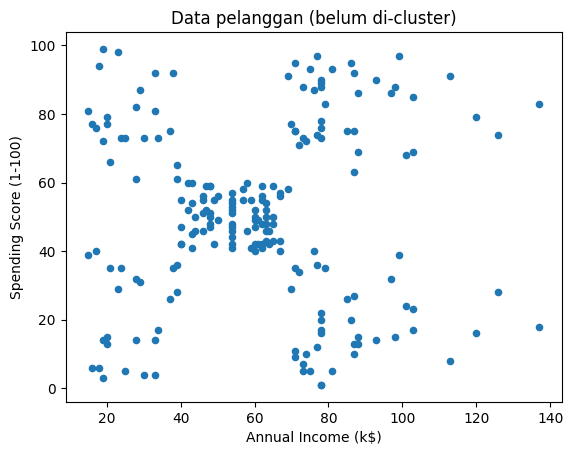

In [2]:
import os
FILE = "Mall_Customers.csv"
if not os.path.exists(FILE):
    try:
        from google.colab import files
        files.upload()      # pilih file Mall_Customers.csv
    except ImportError:
        raise FileNotFoundError(f"Letakkan {FILE} di folder yang sama dengan notebook ini.")

df = pd.read_csv(FILE)
fitur = ["Annual Income (k$)", "Spending Score (1-100)"]
X = df[fitur].values
print("Ukuran data:", df.shape, "| missing value:", df.isnull().sum().sum())
display(df.describe().round(1))

plt.scatter(X[:, 0], X[:, 1], s=20)
plt.xlabel(fitur[0]); plt.ylabel(fitur[1]); plt.title("Data pelanggan (belum di-cluster)")
plt.show()

## Praktikum 10.3 Preprocessing

In [3]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # Scaling WAJIB karena
                                    # K-Means berbasis jarak

## Praktikum 10.4 Training Model

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X_scaled)

agglo = AgglomerativeClustering(n_clusters=3, linkage="ward")
labels_agglo = agglo.fit_predict(X_scaled)

dbscan = DBSCAN(eps=0.3, min_samples=5)
labels_dbscan = dbscan.fit_predict(X_scaled)

## Praktikum 10.5 Evaluasi

In [5]:
print("Silhouette Score K-Means      :", round(silhouette_score(X_scaled, labels_kmeans), 3))
print("Silhouette Score Agglomerative:", round(silhouette_score(X_scaled, labels_agglo), 3))
n_noise = (labels_dbscan == -1).sum()
print("Jumlah noise point (DBSCAN)   :", n_noise)
print("Jumlah cluster DBSCAN         :", len(set(labels_dbscan)) - (1 if -1 in labels_dbscan else 0))

Silhouette Score K-Means      : 0.467
Silhouette Score Agglomerative: 0.461
Jumlah noise point (DBSCAN)   : 35
Jumlah cluster DBSCAN         : 7


## Praktikum 10.6 Visualisasi

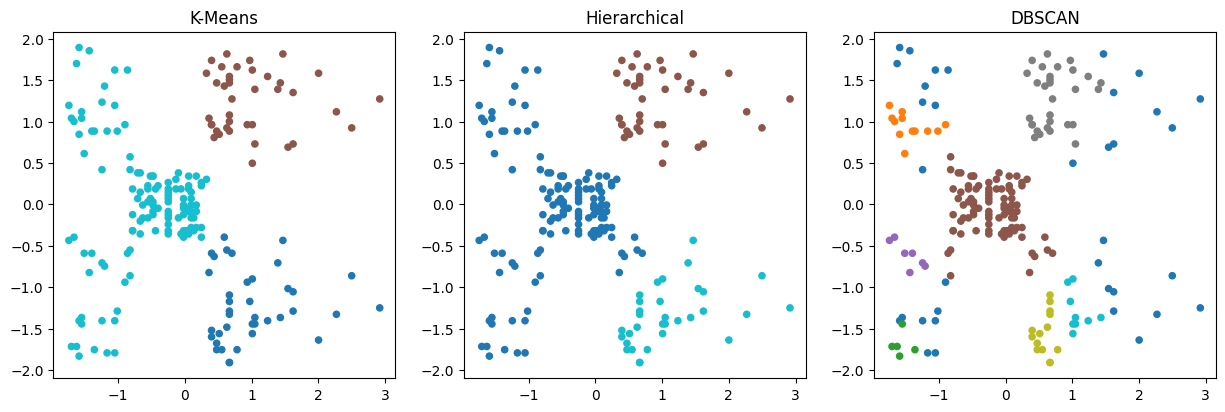

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, labels, judul in zip(axes, [labels_kmeans, labels_agglo, labels_dbscan],
                             ["K-Means", "Hierarchical", "DBSCAN"]):
    ax.scatter(X_scaled[:, 0], X_scaled[:, 1], c=labels, cmap="tab10", s=20)
    ax.set_title(judul)
plt.show()

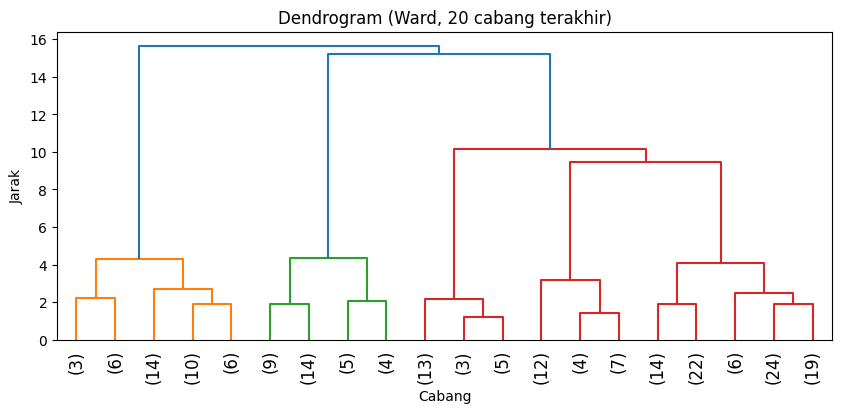

In [7]:
# Tambahan: dendrogram (linkage Ward) untuk Hierarchical Clustering
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90)
plt.title("Dendrogram (Ward, 20 cabang terakhir)"); plt.xlabel("Cabang"); plt.ylabel("Jarak")
plt.show()

### 10.11.1 Interpretasi

- Dengan **k = 3** (nilai dari buku): Silhouette K-Means **0,467** dan Agglomerative **0,461**, nilainya hampir sama dan tergolong sedang. Ini menjadi petunjuk bahwa k=3 belum optimal, dan Latihan 1 membuktikannya (k optimal = 5).
- **DBSCAN** (eps=0,3, min_samples=5) menemukan **7 cluster** dan **35 noise point** (17,5% dari 200 pelanggan). Banyaknya noise menunjukkan eps=0,3 cukup ketat untuk data ini. Pelanggan noise adalah pola yang tidak masuk segmen utama, mis. pelanggan yang berada di perbatasan antar kelompok atau terlalu jarang.
- Silhouette tinggi berarti cluster padat dan terpisah baik; pada DBSCAN, skor dihitung terpisah pada Latihan 2 karena perlu memperlakukan noise dengan hati-hati.
- Dendrogram: bila dipotong pada jarak sekitar 5–9, terbentuk **5 cabang**; cabang-cabang itu baru bergabung pada jarak ±9–10 dan ±15, jauh di atas jarak penggabungan di dalam tiap cabang (≤ ±4,4). Lompatan jarak yang besar ini mendukung jumlah cluster sekitar 5.

---
## 10.12 Latihan Praktikum

### Praktikum 1: Menentukan k Optimal (Elbow Method dan Silhouette Score, k = 2 sampai 10)

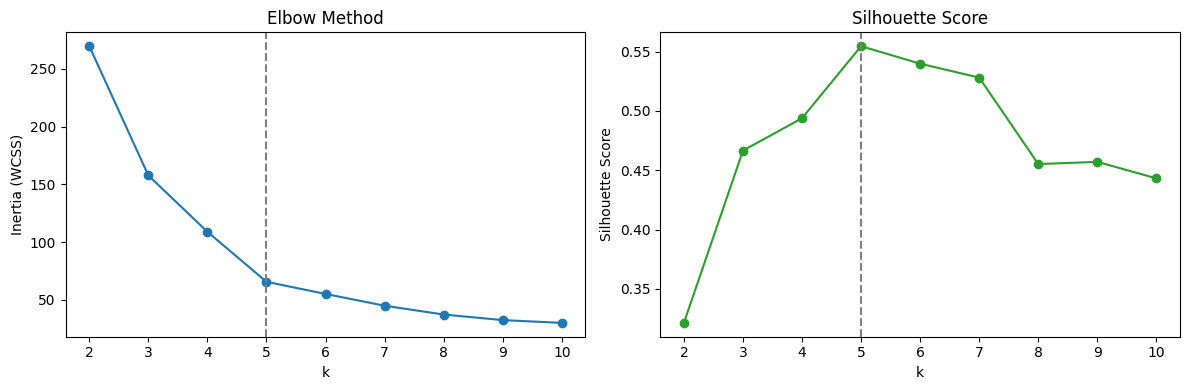

,Inertia,Silhouette,Davies-Bouldin (makin kecil makin baik),Penurunan inertia
k,,,,
2,269.691,0.321,1.267,NaN
3,157.704,0.467,0.716,-112.0
4,108.921,0.494,0.710,-48.8
5,65.568,0.555,0.572,-43.4
6,55.057,0.540,0.655,-10.5
7,44.865,0.528,0.715,-10.2
8,37.228,0.455,0.760,-7.6
9,32.392,0.457,0.763,-4.8
10,29.982,0.443,0.793,-2.4


k terbaik menurut Silhouette: 5


In [8]:
from sklearn.metrics import davies_bouldin_score
ks = range(2, 11)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X_scaled, km.labels_))
    dbi.append(davies_bouldin_score(X_scaled, km.labels_))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.plot(ks, inertia, 'o-'); a1.set_xlabel("k"); a1.set_ylabel("Inertia (WCSS)")
a1.set_title("Elbow Method"); a1.axvline(5, ls='--', color='gray')
a2.plot(ks, sil, 'o-', color="tab:green"); a2.set_xlabel("k"); a2.set_ylabel("Silhouette Score")
a2.set_title("Silhouette Score"); a2.axvline(5, ls='--', color='gray')
plt.tight_layout(); plt.show()

hasil = pd.DataFrame({"k": list(ks), "Inertia": inertia, "Silhouette": sil, "Davies-Bouldin (makin kecil makin baik)": dbi}).round(3)
hasil["Penurunan inertia"] = hasil["Inertia"].diff().round(1)
display(hasil.set_index("k"))
print("k terbaik menurut Silhouette:", list(ks)[int(np.argmax(sil))])

#### Kesimpulan Praktikum 1: **k optimal = 5**

| k | Inertia | Silhouette | Davies-Bouldin |
|---|---|---|---|
| 2 | 269,7 | 0,321 | 1,267 |
| 3 | 157,7 | 0,467 | 0,716 |
| 4 | 108,9 | 0,494 | 0,710 |
| **5** | **65,6** | **0,555** | **0,572** |
| 6 | 55,1 | 0,540 | 0,655 |
| 7 | 44,9 | 0,528 | 0,715 |
| 8–10 | 37,2 → 30,0 | 0,455 → 0,443 | 0,76 → 0,79 |

**Justifikasi:**
1. **Elbow:** inertia turun tajam sampai k = 5 (108,9 → 65,6, turun 43,4), lalu penurunannya jauh lebih landai (k=6 hanya turun 10,5). Siku kurva berada di **k = 5**.
2. **Silhouette:** nilai tertinggi ada di **k = 5 (0,555)**, kemudian menurun (k=6: 0,540).
3. **Davies-Bouldin** (pembanding tambahan) juga terendah di k = 5 (0,572).
4. Ketiga metrik menunjuk ke angka yang sama, jadi k = 5 dapat dipertanggungjawabkan. Hasil ini juga sesuai struktur data: pada scatter plot tampak 5 gerombolan yang jelas (lihat Latihan 2).

### Praktikum 2: Segmentasi dengan Tiga Algoritma (Praktikum 10.7)

K-Means dan Hierarchical memakai **k = 5** (hasil Latihan 1). Untuk DBSCAN, parameter dicari dengan grid kecil karena `eps` dan `min_samples` sangat menentukan hasil.

In [9]:
# Terapkan K-Means, Hierarchical (Agglomerative),
# dan DBSCAN pada dataset yang sama.
km5 = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_scaled)
ag5 = AgglomerativeClustering(n_clusters=5, linkage="ward").fit(X_scaled)

# Cari parameter DBSCAN: tabel eps x min_samples
baris = []
for e in [0.2, 0.3, 0.4, 0.5, 0.6]:
    for ms in [3, 5, 8]:
        l = DBSCAN(eps=e, min_samples=ms).fit_predict(X_scaled)
        m = l != -1; nc = len(set(l[m]))
        baris.append({"eps": e, "min_samples": ms, "cluster": nc, "noise": int((~m).sum()),
                      "silhouette (tanpa noise)": round(silhouette_score(X_scaled[m], l[m]), 3) if nc > 1 else np.nan})
display(pd.DataFrame(baris))

,eps,min_samples,cluster,noise,silhouette (tanpa noise)
0,0.2,3,13,44,0.470
1,0.2,5,7,77,0.586
2,0.2,8,2,116,0.603
3,0.3,3,9,14,0.472
4,0.3,5,7,35,0.524
5,0.3,8,5,72,0.593
6,0.4,3,4,10,0.395
7,0.4,5,4,15,0.478
8,0.4,8,5,25,0.549
9,0.5,3,2,7,0.389


,Jumlah cluster,Noise,Silhouette (semua titik),Silhouette (tanpa noise)
K-Means (k=5),5,0,0.555,0.555
Hierarchical (k=5),5,0,0.554,0.554
"DBSCAN (eps=0.4, ms=8)",5,25,0.415,0.549


Kemiripan K-Means vs Hierarchical (ARI): 0.942
Kemiripan K-Means vs DBSCAN pada titik non-noise (ARI): 0.79


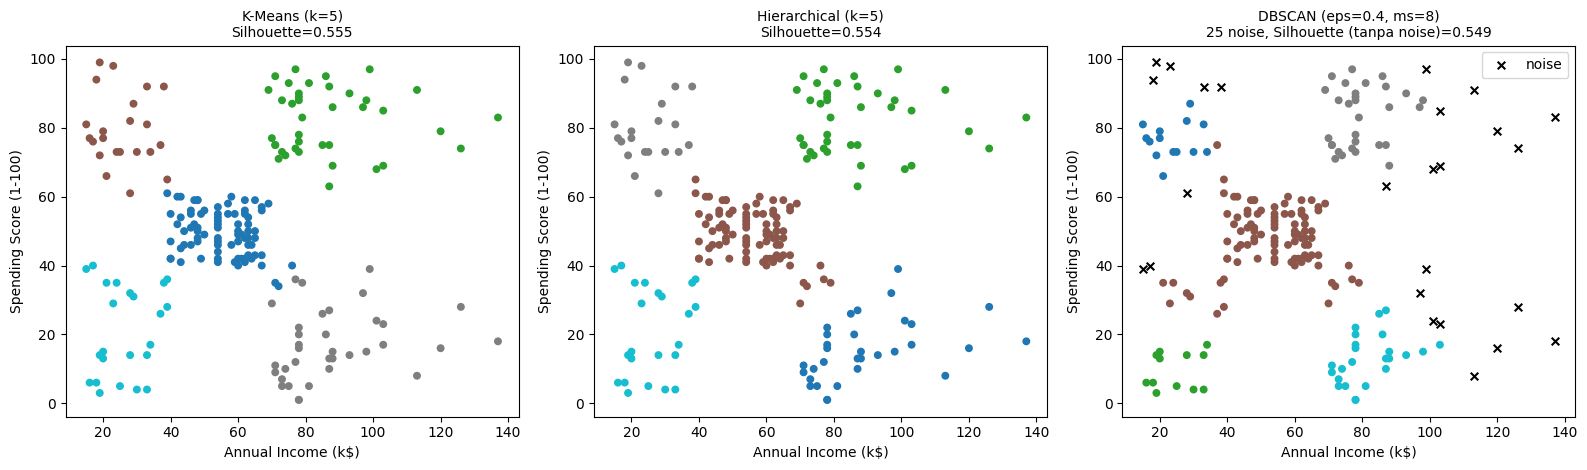

In [10]:
# DBSCAN terpilih: eps=0.4, min_samples=8 (5 cluster, noise relatif sedikit)
db = DBSCAN(eps=0.4, min_samples=8).fit(X_scaled)
l_db = db.labels_; m = l_db != -1

from sklearn.metrics import adjusted_rand_score
ringkas = pd.DataFrame({
    "Jumlah cluster": [5, 5, len(set(l_db[m]))],
    "Noise": [0, 0, int((~m).sum())],
    "Silhouette (semua titik)": [silhouette_score(X_scaled, km5.labels_), silhouette_score(X_scaled, ag5.labels_),
                                 silhouette_score(X_scaled, l_db)],
    "Silhouette (tanpa noise)": [silhouette_score(X_scaled, km5.labels_), silhouette_score(X_scaled, ag5.labels_),
                                 silhouette_score(X_scaled[m], l_db[m])],
}, index=["K-Means (k=5)", "Hierarchical (k=5)", "DBSCAN (eps=0.4, ms=8)"]).round(3)
display(ringkas)
print("Kemiripan K-Means vs Hierarchical (ARI):", round(adjusted_rand_score(km5.labels_, ag5.labels_), 3))
print("Kemiripan K-Means vs DBSCAN pada titik non-noise (ARI):", round(adjusted_rand_score(km5.labels_[m], l_db[m]), 3))

# Bandingkan ketiganya dalam satu figure (subplot), dalam satuan asli
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, labels, judul in zip(axes, [km5.labels_, ag5.labels_, l_db],
        [f"K-Means (k=5)\nSilhouette={silhouette_score(X_scaled, km5.labels_):.3f}",
         f"Hierarchical (k=5)\nSilhouette={silhouette_score(X_scaled, ag5.labels_):.3f}",
         f"DBSCAN (eps=0.4, ms=8)\n{(~m).sum()} noise, Silhouette (tanpa noise)={silhouette_score(X_scaled[m], l_db[m]):.3f}"]):
    ax.scatter(X[labels != -1, 0], X[labels != -1, 1], c=labels[labels != -1], cmap="tab10", s=22)
    if (labels == -1).any():
        ax.scatter(X[labels == -1, 0], X[labels == -1, 1], c="k", marker="x", s=30, label="noise")
        ax.legend()
    ax.set_title(judul, fontsize=10); ax.set_xlabel(fitur[0]); ax.set_ylabel(fitur[1])
plt.tight_layout(); plt.show()

In [11]:
# Profil segmen dari K-Means (k=5) untuk interpretasi bisnis
df["Segmen"] = km5.labels_
profil = df.groupby("Segmen")[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].mean().round(1)
profil["Jumlah"] = df.groupby("Segmen").size()
display(profil)

,Age,Annual Income (k$),Spending Score (1-100),Jumlah
Segmen,,,,
0,42.7,55.3,49.5,81
1,32.7,86.5,82.1,39
2,25.3,25.7,79.4,22
3,41.1,88.2,17.1,35
4,45.2,26.3,20.9,23


#### Kesimpulan Praktikum 2

| Algoritma | Cluster | Noise | Silhouette |
|---|---|---|---|
| K-Means (k=5) | 5 | 0 | **0,555** |
| Hierarchical Ward (k=5) | 5 | 0 | 0,554 |
| DBSCAN (eps=0,4, min_samples=8) | 5 | 25 | 0,549 (tanpa noise), 0,415 (dengan noise sebagai satu kelompok) |

- **K-Means dan Hierarchical hampir identik** (ARI = 0,942, Silhouette 0,555 vs 0,554). Pada data yang bergerombol bulat dan terpisah jelas seperti ini, kedua algoritma menemukan segmen yang sama.
- **DBSCAN** menemukan 5 cluster juga, tetapi harus mengeluarkan **25 pelanggan (12,5%) sebagai noise**. Ia sangat sensitif terhadap `eps`: eps=0,3 memecah data menjadi 7 cluster dengan 35 noise, sedangkan eps ≥ 0,5 hanya menghasilkan 2 cluster. Pada gambar, titik noise terutama berada di tepi kelompok dan pada pelanggan berpendapatan tinggi (> 100k$) yang jumlahnya jarang, sehingga tidak cukup padat untuk membentuk cluster. Skor silhouette DBSCAN tidak dapat dibandingkan langsung karena noise dikeluarkan.
- **Paling masuk akal untuk bisnis: K-Means (k=5).** Setiap pelanggan masuk ke satu segmen sehingga bisa langsung ditargetkan, jumlah segmen dapat ditentukan dan dibenarkan (Latihan 1), hasilnya mudah dijelaskan lewat rata-rata tiap segmen, dan stabil (hampir sama dengan Hierarchical). DBSCAN berguna sebagai pelengkap untuk mendeteksi pelanggan yang tidak biasa.

**Profil segmen K-Means (k=5):**

| Segmen | Usia rata-rata | Pendapatan (k$) | Spending Score | Jumlah | Interpretasi |
|---|---|---|---|---|---|
| 1 | 32,7 | 86,5 | 82,1 | 39 | **Pelanggan premium**: pendapatan tinggi dan belanja tinggi, prioritas program loyalitas |
| 2 | 25,3 | 25,7 | 79,4 | 22 | **Muda dan konsumtif**: pendapatan rendah tetapi belanja tinggi, cocok promo/diskon |
| 3 | 41,1 | 88,2 | 17,1 | 35 | **Berpenghasilan tinggi tetapi hemat**: potensi besar yang belum tergarap |
| 4 | 45,2 | 26,3 | 20,9 | 23 | **Hemat dan berpenghasilan rendah**: prioritas pemasaran paling rendah |
| 0 | 42,7 | 55,3 | 49,5 | 81 | **Pelanggan menengah**: segmen terbesar, perilaku rata-rata |

Catatan: nomor segmen bisa berbeda di tiap eksekusi, tetapi karena `random_state=42` hasilnya tetap sama jika kode dijalankan ulang dengan data yang sama.